LOAD AND CHECK DATA

The file is split by unique sentence, and the check below proves no sentence appears in both sets.

In [13]:
import sys, os

In [14]:
HELPERS_FOLDER = r"C:\Users\vhona"
HELPERS_FILE = os.path.join(HELPERS_FOLDER, "helpers.py")

In [15]:
if HELPERS_FOLDER not in sys.path:
    sys.path.insert(0, HELPERS_FOLDER)
sys.modules.pop('helpers', None)

<module 'helpers' from 'C:\\Users\\vhona\\helpers.py'>

In [16]:
if not os.path.exists(HELPERS_FILE):
    raise FileNotFoundError(f"helpers.py was not found at {HELPERS_FILE}. Save File 1 from the HTML file at that location first.")
with open(HELPERS_FILE, encoding='utf-8', errors='ignore') as fh:
    if 'def load_all' not in fh.read():
        raise ValueError(f"The file at {HELPERS_FILE} is the OLD helpers.py. Replace its contents with File 1 from the HTML file, save it, then run this cell again.")

In [17]:
from helpers import load_data, load_all, display
all_data = load_all()
train, valid = load_data()
print('Loaded helpers from:', sys.modules['helpers'].__file__)

Loaded helpers from: C:\Users\vhona\helpers.py


In [18]:
print('All rows:', all_data.shape[0], '| Unique sentences:', all_data['text'].nunique())
print('Train rows:', train.shape[0], '| Valid rows:', valid.shape[0])
print('Sentences in BOTH train and valid (0 means no leakage):', len(set(train['text']) & set(valid['text'])))

All rows: 1000 | Unique sentences: 20
Train rows: 808 | Valid rows: 192
Sentences in BOTH train and valid (0 means no leakage): 0


In [19]:
display(all_data[['text', 'clean_text', 'category']].drop_duplicates('text').head())

,text,clean_text,category
0,Immunotherapy has shown promise in treating metastatic melanoma.,immunotherapy shown promise treating metastatic melanoma,Cancer
1,The relationship between obesity and type 2 diabetes is well established.,relationship obesity type diabetes well established,Diabetes
2,Recent trials show the efficacy of SGLT2 inhibitors in reducing HbA1c.,recent trials show efficacy sglt2 inhibitors reducing hba1c,Diabetes
3,BRCA mutations significantly increase the risk of breast and ovarian cancers.,brca mutations significantly increase risk breast ovarian cancers,Cancer
5,Beta-blockers are essential for managing chronic heart failure.,beta blockers essential managing chronic heart failure,Cardiology


The preview compares each original sentence with its cleaned version.

CATEGORY COUNTS IN BOTH SETS

This shows the rows per category in each set and how many unique sentences each category has.

In [20]:
from helpers import load_data, load_all, pd, display
all_data = load_all()
train, valid = load_data()

display(pd.concat([train['category'].value_counts().rename('train rows'),
                   valid['category'].value_counts().rename('valid rows'),
                   all_data.groupby('category')['text'].nunique().rename('unique sentences')], axis=1))

,train rows,valid rows,unique sentences
category,,,
Cancer,212,38,5
Diabetes,202,48,5
Hypertension,201,49,5
Cardiology,193,57,5


Each category has the same number of rows, so the classes are balanced.

CATERORY DISTRIBUTION CHART (Figure 1)

This chart shows the balance of the four medical categories.

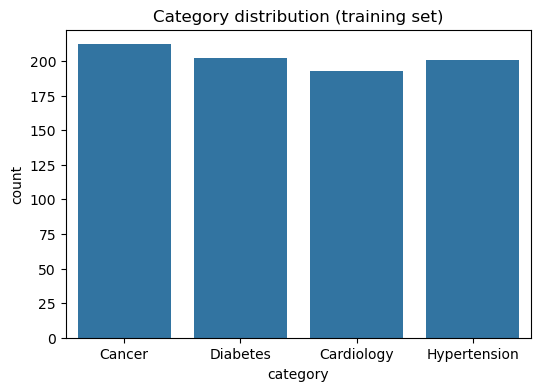

In [21]:
%matplotlib inline
from helpers import load_data, plt, sns
train, valid = load_data()

plt.figure(figsize=(6, 4))
sns.countplot(x='category', data=train)
plt.title('Category distribution (training set)')
plt.show()

Equal bars mean the four medical categories are balanced, so accuracy is a fair measure of performance here.

TEXT LENGTH (Figure 2)

The histogram shows how long the sentences are, and the boxplot compares lengths across categories.

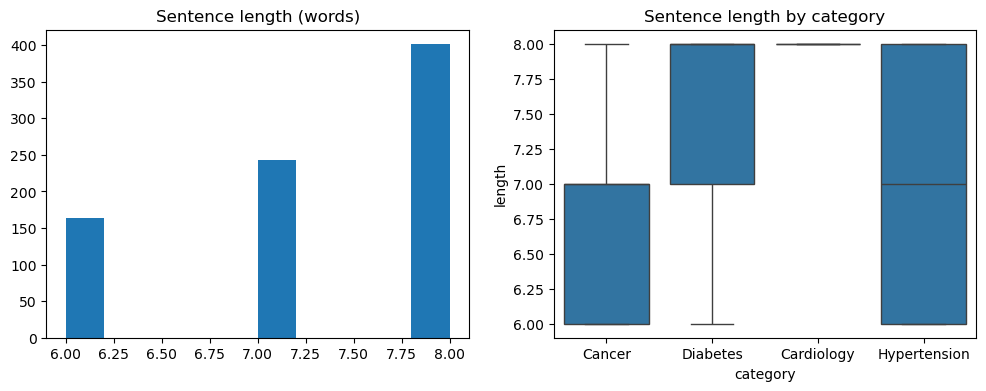

In [22]:
%matplotlib inline
from helpers import load_data, plt, sns
train, valid = load_data()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(train['length'], bins=10)
ax[0].set_title('Sentence length (words)')
sns.boxplot(x='category', y='length', data=train, showfliers=False, ax=ax[1])
ax[1].set_title('Sentence length by category')
plt.show()

The sentences are short, with a narrow spread of lengths.

OUTLIERS

Unusually long sentences are counted with the interquartile range method.

In [23]:
from helpers import load_data
train, valid = load_data()

Q1, Q3 = train['length'].quantile([0.25, 0.75])
upper = Q3 + 1.5 * (Q3 - Q1)
print(f"Median length: {train['length'].median():.0f} words")
print(f"Long-sentence outliers (> {upper:.0f} words): {(train['length'] > upper).sum()}")

Median length: 7 words
Long-sentence outliers (> 10 words): 0


TOP 20 WORDS (Figure 3)

This plots the 20 most common words across the training sentences.

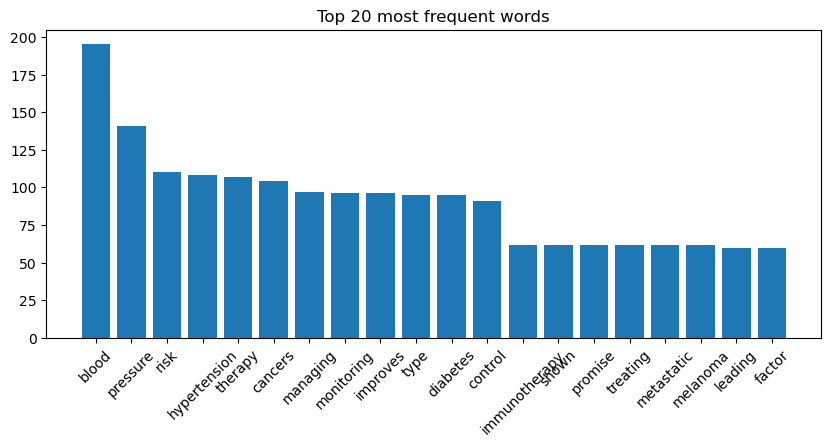

In [24]:
%matplotlib inline
from helpers import load_data, plt, Counter
train, valid = load_data()

words = ' '.join(train['clean_text']).split()
labels, counts = zip(*Counter(words).most_common(20))
plt.figure(figsize=(10, 4))
plt.bar(labels, counts)
plt.xticks(rotation=45)
plt.title('Top 20 most frequent words')
plt.show()

Repeated sentences make some counts large, so read this chart as a vocabulary guide rather than a frequency in real data.

WORD CLOUD (Figure 4)

The word cloud shows the same frequencies visually, with larger words appearing more often.

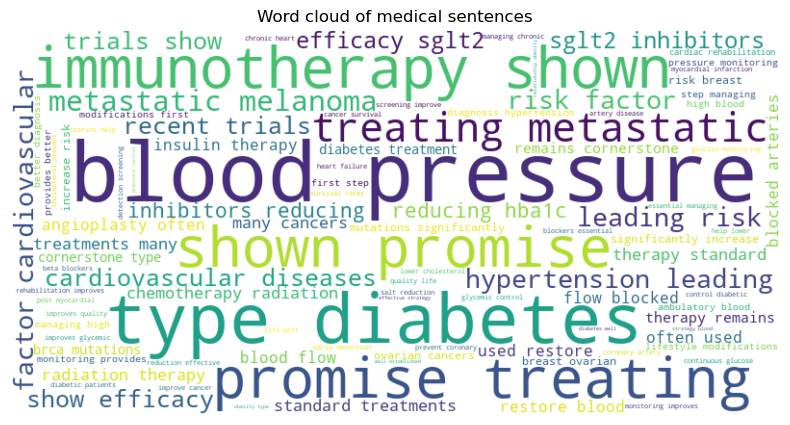

In [25]:
%matplotlib inline
from helpers import load_data, plt, WordCloud
train, valid = load_data()

wc = WordCloud(width=800, height=400, background_color='white').generate(' '.join(train['clean_text']))
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud of medical sentences')
plt.show()

Larger words are more frequent.

VOCABULARY BY CATEGORY

Comparing the top words in each category shows which words identify each medical field.

In [26]:
from helpers import load_data, Counter
train, valid = load_data()

for c in sorted(train['category'].unique()):
    w = ' '.join(train.loc[train['category'] == c, 'clean_text']).split()
    print(f"Top words in {c}:", [x for x, _ in Counter(w).most_common(10)])

Top words in Cancer: ['cancers', 'immunotherapy', 'shown', 'promise', 'treating', 'metastatic', 'melanoma', 'chemotherapy', 'radiation', 'therapy']
Top words in Cardiology: ['angioplasty', 'often', 'used', 'restore', 'blood', 'flow', 'blocked', 'arteries', 'cardiac', 'rehabilitation']
Top words in Diabetes: ['type', 'diabetes', 'recent', 'trials', 'show', 'efficacy', 'sglt2', 'inhibitors', 'reducing', 'hba1c']
Top words in Hypertension: ['blood', 'pressure', 'hypertension', 'leading', 'risk', 'factor', 'cardiovascular', 'diseases', 'lifestyle', 'modifications']


These words are the features the classifier will rely on.


TOPIC MODELLING(LDA) AND CATEGORY CHECK

LDA finds four topics without seeing the labels, and the table shows how well they match the real categories.

In [27]:
from helpers import load_all, fit_lda, pd, display
all_data = load_all()

print('--- Topics across ALL sentences ---')
lda, cv, doc_topics = fit_lda(all_data['clean_text'])

all_data = all_data.assign(topic=doc_topics.argmax(axis=1) + 1)
display(pd.crosstab(all_data['topic'], all_data['category']))

--- Topics across ALL sentences ---
Topic 1: treatment, cancer, therapy, type, diabetes, insulin, remains, cornerstone, rates, early
Topic 2: hypertension, melanoma, immunotherapy, shown, treating, promise, metastatic, leading, cardiovascular, factor
Topic 3: diabetes, inhibitors, efficacy, reducing, trials, recent, show, sglt2, hba1c, cardiology
Topic 4: blood, cancers, pressure, control, flow, angioplasty, restore, arteries, blocked, chemotherapy


category,Cancer,Cardiology,Diabetes,Hypertension
topic,,,,
1,84,0,53,0
2,62,91,0,157
3,0,105,149,0
4,104,54,48,93


A topic that is mostly one category shows the model rediscovered that medical field on its own.

TOPIC CHART

Each panel shows the eight strongest words in one topic, which you use to name the topic.

In [28]:
%matplotlib inline
from helpers import load_all, fit_lda, N_TOPICS, plt
all_data = load_all()
lda, cv, doc_topics = fit_lda(all_data['clean_text'])

Topic 1: treatment, cancer, therapy, type, diabetes, insulin, remains, cornerstone, rates, early
Topic 2: hypertension, melanoma, immunotherapy, shown, treating, promise, metastatic, leading, cardiovascular, factor
Topic 3: diabetes, inhibitors, efficacy, reducing, trials, recent, show, sglt2, hba1c, cardiology
Topic 4: blood, cancers, pressure, control, flow, angioplasty, restore, arteries, blocked, chemotherapy


This refits the topics so the cell works on its own.

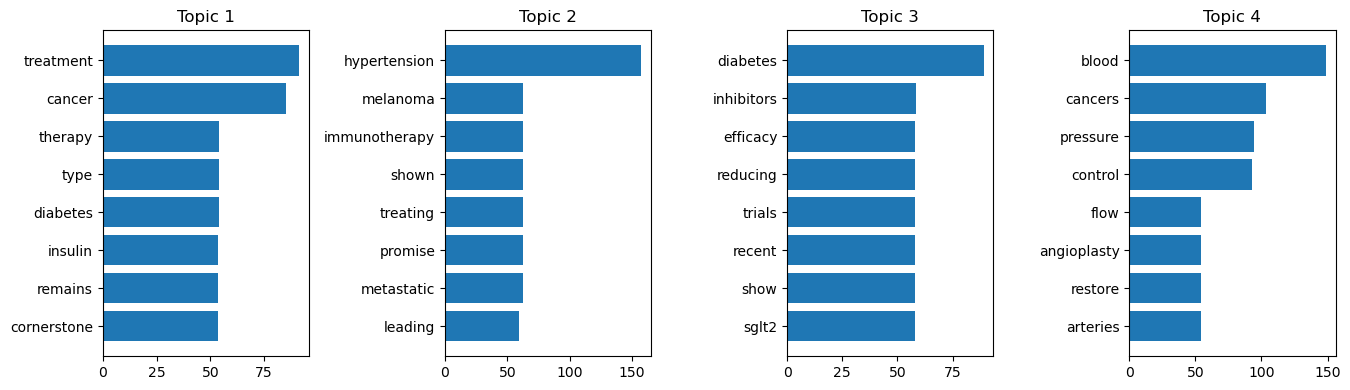

In [29]:
terms = cv.get_feature_names_out()
fig, axes = plt.subplots(1, N_TOPICS, figsize=(3.4 * N_TOPICS, 4))
for i, (ax, comp) in enumerate(zip(axes, lda.components_)):
    idx = comp.argsort()[-8:]
    ax.barh(terms[idx], comp[idx])
    ax.set_title(f'Topic {i + 1}')
plt.tight_layout()
plt.show()

FEATURE SELECTION RESULTS

This shows how many TF-IDF terms were removed because their link to the category was not significant.

In [30]:
from helpers import get_features, np
f = get_features()

In [31]:
print(f"Features before selection: {f['n_before']} | after p < 0.05: {f['n_after']}")
top_idx = np.argsort(np.nan_to_num(f['chi_scores']))[::-1][:15]
print('Most discriminating terms:', list(f['terms'][top_idx]))

Features before selection: 200 | after p < 0.05: 200
Most discriminating terms: ['pressure', 'blood pressure', 'hypertension', 'diabetes', 'type diabetes', 'type', 'cancers', 'factor cardiovascular', 'cardiovascular', 'cardiovascular diseases', 'risk factor', 'diseases', 'factor', 'leading', 'leading risk']


These terms best separate the four medical categories.

CHI-SQAURE CHART

This chart shows how strongly each of the top terms is linked to a category.

In [32]:
%matplotlib inline
from helpers import get_features, np, plt
f = get_features()
top_idx = np.argsort(np.nan_to_num(f['chi_scores']))[::-1][:15]

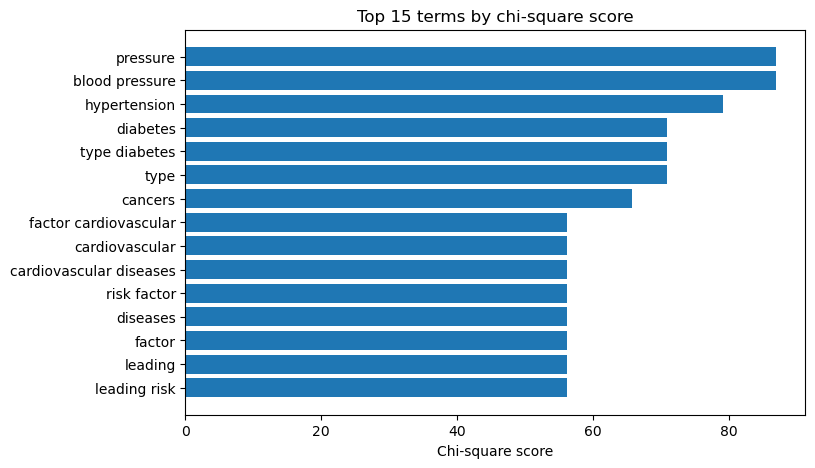

In [33]:
plt.figure(figsize=(8, 5))
plt.barh(f['terms'][top_idx][::-1], np.nan_to_num(f['chi_scores'])[top_idx][::-1])
plt.title('Top 15 terms by chi-square score')
plt.xlabel('Chi-square score')
plt.show()

A longer bar means a stronger link to a category.

TRAIN AND EVALUATE BASELINE MODELS

Both baselines are trained with default settings and scored on sentences they have never seen.

In [34]:
%matplotlib inline
from helpers import get_features, train_baselines, evaluate
f = get_features()
log_reg, nb_model = train_baselines()


=== Logistic Regression (baseline) ===
              precision    recall  f1-score   support

      Cancer       0.40      1.00      0.57        38
  Cardiology       0.00      0.00      0.00        57
    Diabetes       1.00      1.00      1.00        48
Hypertension       0.00      0.00      0.00        49

    accuracy                           0.45       192
   macro avg       0.35      0.50      0.39       192
weighted avg       0.33      0.45      0.36       192



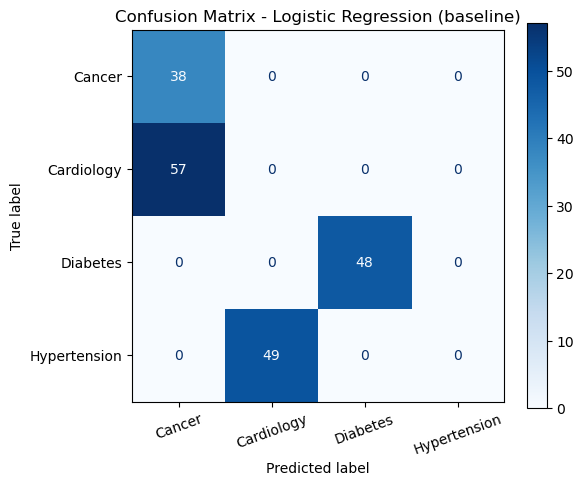


=== Naive Bayes (baseline) ===
              precision    recall  f1-score   support

      Cancer       0.00      0.00      0.00        38
  Cardiology       0.00      0.00      0.00        57
    Diabetes       0.56      1.00      0.72        48
Hypertension       1.00      1.00      1.00        49

    accuracy                           0.51       192
   macro avg       0.39      0.50      0.43       192
weighted avg       0.39      0.51      0.43       192



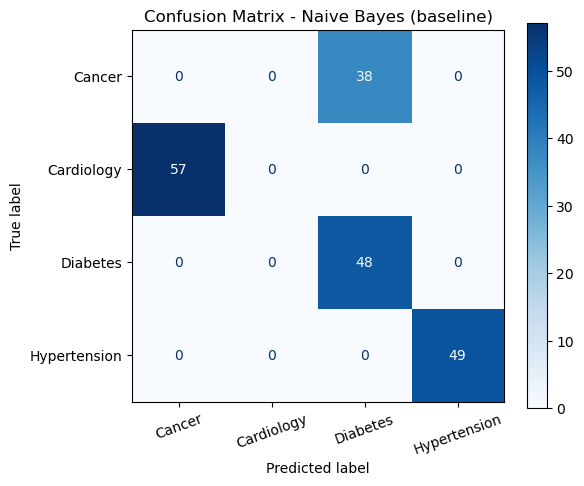

In [35]:
_ = evaluate(log_reg, f['X_test'], f['y_test'], 'Logistic Regression (baseline)')
_ = evaluate(nb_model, f['X_test'], f['y_test'], 'Naive Bayes (baseline)')

Each call prints a classification report and draws a confusion matrix.

RETRAIN TUNED PARAMETERS

Grid search tests four values of the regularisation strength C, using cross-validation that keeps copies of one sentence together.

In [36]:
%matplotlib inline
from helpers import get_tuned, get_features, evaluate
f = get_features()

Best parameters: {'C': 0.1}

=== Logistic Regression (tuned) ===
              precision    recall  f1-score   support

      Cancer       0.40      1.00      0.57        38
  Cardiology       0.00      0.00      0.00        57
    Diabetes       1.00      1.00      1.00        48
Hypertension       1.00      1.00      1.00        49

    accuracy                           0.70       192
   macro avg       0.60      0.75      0.64       192
weighted avg       0.58      0.70      0.62       192



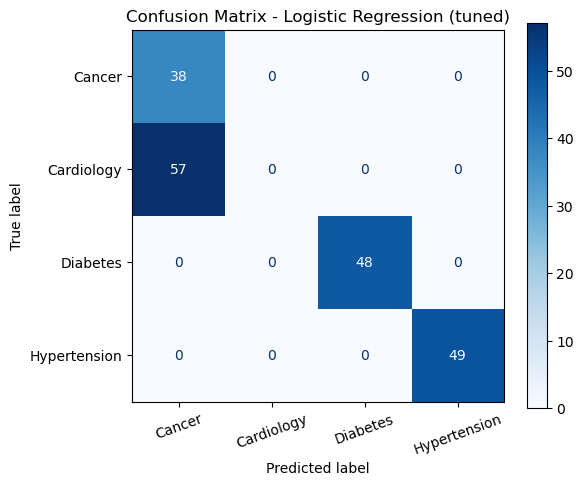

In [37]:
grid = get_tuned()
print('Best parameters:', grid.best_params_)
_ = evaluate(grid.best_estimator_, f['X_test'], f['y_test'], 'Logistic Regression (tuned)')

The tuned model is scored on the validation sentences and its confusion matrix is drawn.

COMPARISON TABLE AND CHARTS

This compares the three models in one table, then charts the key metrics and the recall for each category.

In [38]:
%matplotlib inline
from helpers import get_features, train_baselines, get_tuned, get_results, display, pd, plt, recall_score, FOCUS
f = get_features()
log_reg, nb_model = train_baselines()
grid = get_tuned()
comparison = get_results()
display(comparison)

,Accuracy,Macro Precision,Macro Recall,Macro F1,Cancer Recall
Model,,,,,
LR baseline,0.448,0.35,0.50,0.393,1.0
NB baseline,0.505,0.39,0.50,0.429,0.0
LR tuned,0.703,0.60,0.75,0.643,1.0


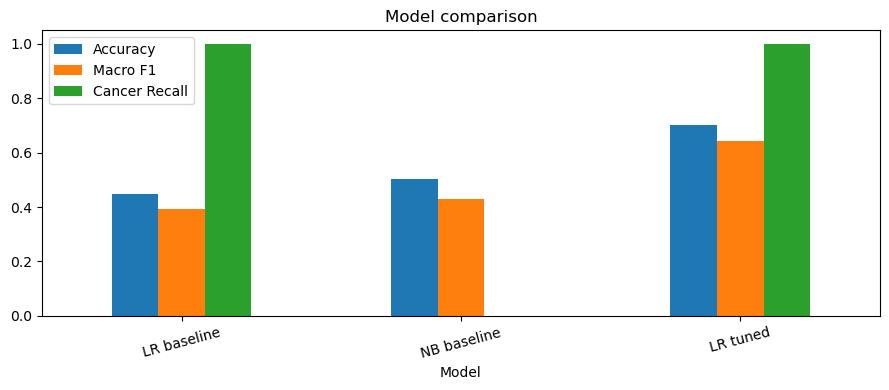

In [39]:
comparison[['Accuracy', 'Macro F1', f'{FOCUS} Recall']].plot(kind='bar', figsize=(9, 4))
plt.title('Model comparison')
plt.xticks(rotation=15)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()


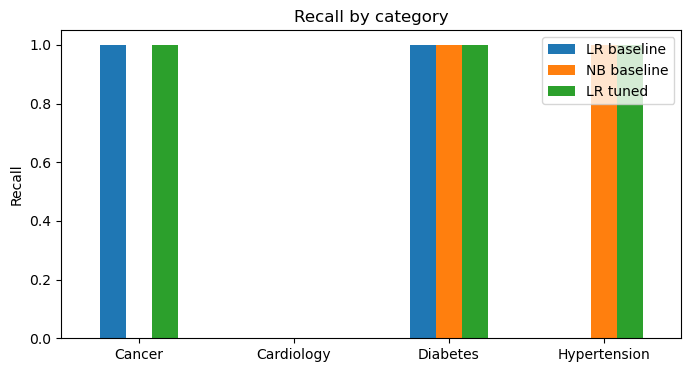

In [40]:
classes = sorted(f['y_test'].unique())
models = {'LR baseline': log_reg, 'NB baseline': nb_model, 'LR tuned': grid.best_estimator_}
recall_df = pd.DataFrame({n: recall_score(f['y_test'], m.predict(f['X_test']), labels=classes,
                                          average=None, zero_division=0) for n, m in models.items()}, index=classes)
recall_df.plot(kind='bar', figsize=(8, 4))
plt.title('Recall by category')
plt.ylabel('Recall')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.show()

EXAMPLE SENTENCES FOR EACH CATEGORY

Gives two real sentences per category, so the report can show what each category looks like.

In [41]:
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import load_all, pd, display
all_data = load_all()
pd.set_option('display.max_colwidth', 120)

examples = all_data.drop_duplicates('text').groupby('category').head(2).sort_values('category')[['category', 'text', 'clean_text']]
display(examples.reset_index(drop=True))

,category,text,clean_text
0,Cancer,Immunotherapy has shown promise in treating metastatic melanoma.,immunotherapy shown promise treating metastatic melanoma
1,Cancer,BRCA mutations significantly increase the risk of breast and ovarian cancers.,brca mutations significantly increase risk breast ovarian cancers
2,Cardiology,Beta-blockers are essential for managing chronic heart failure.,beta blockers essential managing chronic heart failure
3,Cardiology,Angioplasty is often used to restore blood flow in blocked arteries.,angioplasty often used restore blood flow blocked arteries
4,Diabetes,The relationship between obesity and type 2 diabetes is well established.,relationship obesity type diabetes well established
5,Diabetes,Recent trials show the efficacy of SGLT2 inhibitors in reducing HbA1c.,recent trials show efficacy sglt2 inhibitors reducing hba1c
6,Hypertension,Ambulatory blood pressure monitoring provides better diagnosis of hypertension.,ambulatory blood pressure monitoring provides better diagnosis hypertension
7,Hypertension,Salt reduction is an effective strategy for blood pressure control.,salt reduction effective strategy blood pressure control


Each row shows the original sentence and what the model actually sees after cleaning.

DATA QAULITY TABLE

In [42]:
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import quality_table, display
display(quality_table())

,Raw rows,Missing text or label,Duplicate rows,Unique sentences,Empty after cleaning,Final rows,Average words,Vocabulary size
Dataset,1000,0,980,20,0,1000,7.0,118


This table proves the data was checked, and it shows that 1,000 rows contain only 20 unique sentences.

MODEL SETTING TABLE

Lists every setting used, for the methodology section and the appendix.

In [43]:
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import get_features, get_tuned, pd, display, N_TOPICS, RANDOM_STATE
f = get_features()
grid = get_tuned()

settings = pd.DataFrame([
    ['Split', 'About 20% of the unique sentences in each category held out for validation'],
    ['TF-IDF', 'max_features=10000, ngram_range=(1, 2), min_df=2'],
    ['Feature selection', f"chi-square, keep p < 0.05 (kept {f['n_after']} of {f['n_before']} terms)"],
    ['Logistic Regression (baseline)', 'C=1, max_iter=1000'],
    ['Naive Bayes (baseline)', 'alpha=1.0 (default)'],
    ['Grid search', 'C in {0.1, 1, 10, 100}; 3-fold stratified group cross-validation; scoring=f1_macro'],
    ['Tuned Logistic Regression', str(grid.best_params_)],
    ['LDA', f'{N_TOPICS} topics, max_df=0.5, min_df=5, max_iter=10, online learning'],
    ['Random state', RANDOM_STATE]], columns=['Component', 'Setting']).set_index('Component')
display(settings)

,Setting
Component,
Split,About 20% of the unique sentences in each category held out for validation
TF-IDF,"max_features=10000, ngram_range=(1, 2), min_df=2"
Feature selection,"chi-square, keep p < 0.05 (kept 200 of 200 terms)"
Logistic Regression (baseline),"C=1, max_iter=1000"
Naive Bayes (baseline),alpha=1.0 (default)
Grid search,"C in {0.1, 1, 10, 100}; 3-fold stratified group cross-validation; scoring=f1_macro"
Tuned Logistic Regression,{'C': 0.1}
LDA,"4 topics, max_df=0.5, min_df=5, max_iter=10, online learning"
Random state,42


CLASSIFICATION QAULITY BY CATEGORY

Shows precision, recall, F1 and support for each category and each model.

In [44]:
%matplotlib inline
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import get_features, train_baselines, get_tuned, report_table, accuracy_score, display, plt
f = get_features()
log_reg, nb_model = train_baselines()
grid = get_tuned()
models = {'Logistic Regression (baseline)': log_reg, 'Naive Bayes (baseline)': nb_model, 'Logistic Regression (tuned)': grid.best_estimator_}

for name, m in models.items():
    print(f"\n{name} | accuracy: {accuracy_score(f['y_test'], m.predict(f['X_test'])):.3f}")
    display(report_table(m, f['X_test'], f['y_test']))


Logistic Regression (baseline) | accuracy: 0.448


,precision,recall,f1-score,support
Cancer,0.400,1.000,0.571,38.0
Cardiology,0.000,0.000,0.000,57.0
Diabetes,1.000,1.000,1.000,48.0
Hypertension,0.000,0.000,0.000,49.0
macro avg,0.350,0.500,0.393,192.0
weighted avg,0.329,0.448,0.363,192.0



Naive Bayes (baseline) | accuracy: 0.505


,precision,recall,f1-score,support
Cancer,0.000,0.000,0.000,38.0
Cardiology,0.000,0.000,0.000,57.0
Diabetes,0.558,1.000,0.716,48.0
Hypertension,1.000,1.000,1.000,49.0
macro avg,0.390,0.500,0.429,192.0
weighted avg,0.395,0.505,0.434,192.0



Logistic Regression (tuned) | accuracy: 0.703


,precision,recall,f1-score,support
Cancer,0.400,1.000,0.571,38.0
Cardiology,0.000,0.000,0.000,57.0
Diabetes,1.000,1.000,1.000,48.0
Hypertension,1.000,1.000,1.000,49.0
macro avg,0.600,0.750,0.643,192.0
weighted avg,0.584,0.703,0.618,192.0


Each table gives precision, recall and F1 per category, plus the macro and weighted averages.

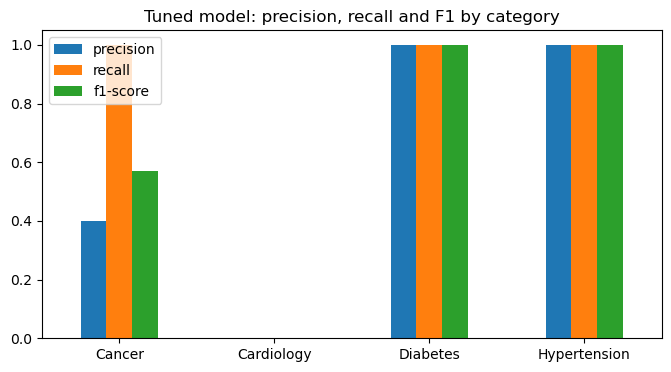

In [45]:
rep = report_table(grid.best_estimator_, f['X_test'], f['y_test'])
classes = sorted(f['y_test'].unique())
rep.loc[classes, ['precision', 'recall', 'f1-score']].plot(kind='bar', figsize=(8, 4))
plt.title('Tuned model: precision, recall and F1 by category')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.show()

The chart makes it easy to see which category is weakest.

CONFUSION MATRIX, COUNTS AND PERCENTAGES

Shows the confusion matrix as counts and as row percentages, with true positives, false positives and false negatives per category.

In [46]:
%matplotlib inline
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import get_features, get_tuned, confusion_table, ConfusionMatrixDisplay, plt, display
f = get_features()
grid = get_tuned()
cm, labels, cm_table = confusion_table(grid.best_estimator_, f['X_test'], f['y_test'])


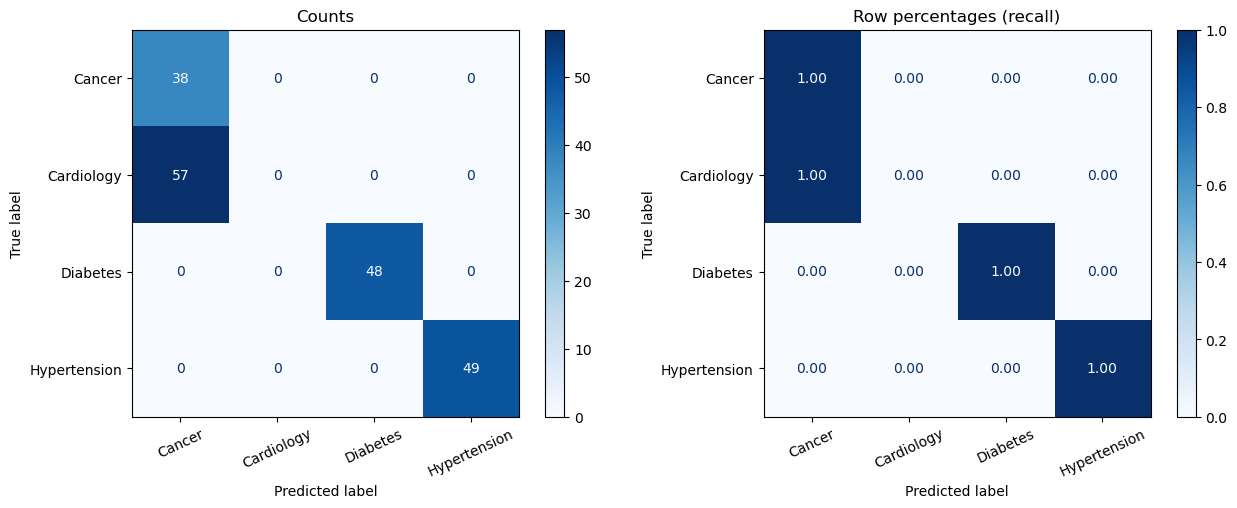

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues', ax=ax[0])
ax[0].set_title('Counts')
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=labels).plot(cmap='Blues', ax=ax[1], values_format='.2f')
ax[1].set_title('Row percentages (recall)')
for a in ax:
    a.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

Rows are the real categories and columns are the predictions. The diagonal of the right-hand chart is each category's recall.

In [48]:
display(cm_table)

,TP,FP,FN,Precision,Recall
Category,,,,,
Cancer,38,57,0,0.4,1.0
Cardiology,0,0,57,0.0,0.0
Diabetes,48,0,0,1.0,1.0
Hypertension,49,0,0,1.0,1.0


TP is correct, FP is wrongly predicted as this category, and FN is a real sentence of this category that was missed.

VALIDATION CHECKS

Checks for overfitting, stability and the majority baseline.

In [49]:
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import load_data, get_features, get_tuned, StratifiedGroupKFold, cross_val_score, LogisticRegression, accuracy_score, f1_score, pd, display, RANDOM_STATE
train, valid = load_data()
f = get_features()
grid = get_tuned()
best = grid.best_estimator_

In [50]:
groups = pd.factorize(train['text'])[0]
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(LogisticRegression(max_iter=1000, **grid.best_params_), f['X_train'], f['y_train'],
                         cv=cv, groups=groups, scoring='f1_macro')
print(f"Grouped 3-fold macro F1 on training data: mean {scores.mean():.3f} | std {scores.std():.3f}")

Grouped 3-fold macro F1 on training data: mean 0.197 | std 0.144


Copies of one sentence stay together in a fold, so this score is not inflated by repeated sentences.

In [51]:
tr_pred, te_pred = best.predict(f['X_train']), best.predict(f['X_test'])
display(pd.DataFrame({'Accuracy': [accuracy_score(f['y_train'], tr_pred), accuracy_score(f['y_test'], te_pred)],
                      'Macro F1': [f1_score(f['y_train'], tr_pred, average='macro'), f1_score(f['y_test'], te_pred, average='macro')]},
                     index=['Training', 'Validation']).round(3))

,Accuracy,Macro F1
Training,1.000,1.000
Validation,0.703,0.643


A large drop from training to validation signals overfitting to the training sentences.

In [52]:
print(f"Unique validation sentences: {valid['text'].nunique()}")
print(f"Majority-class baseline accuracy: {valid['category'].value_counts(normalize=True).max():.3f}")

Unique validation sentences: 4
Majority-class baseline accuracy: 0.297


The validation set holds very few distinct sentences, and the model must beat the majority baseline.

STABILITY ACROSS DIFFERENT HELD-OUT SENTENCES

In [54]:
%matplotlib inline
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import load_all, split_by_sentence, get_tuned, TfidfVectorizer, LogisticRegression, accuracy_score, f1_score, pd, plt, display
all_data = load_all()
best_c = get_tuned().best_params_['C']

rows = []
for seed in range(10):
    tr, va = split_by_sentence(all_data, seed=seed)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
    Xtr, Xva = vec.fit_transform(tr['clean_text']), vec.transform(va['clean_text'])
    pred = LogisticRegression(max_iter=1000, C=best_c).fit(Xtr, tr['category']).predict(Xva)
    rows.append({'Seed': seed, 'Accuracy': accuracy_score(va['category'], pred), 'Macro F1': f1_score(va['category'], pred, average='macro')})
results = pd.DataFrame(rows).set_index('Seed').round(3)
display(results)
print(f"Accuracy: mean {results['Accuracy'].mean():.3f} | std {results['Accuracy'].std():.3f}")


,Accuracy,Macro F1
Seed,,
0,0.738,0.662
1,0.744,0.662
2,0.753,0.662
3,0.750,0.669
4,0.467,0.362
5,0.713,0.662
6,0.459,0.404
7,0.478,0.405
8,0.466,0.318


Accuracy: mean 0.627 | std 0.138


 A large spread means the result depends heavily on which few sentences are held out.

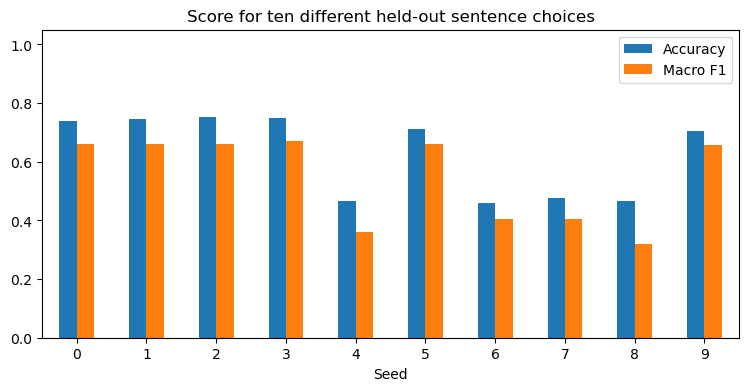

In [55]:
results.plot(kind='bar', figsize=(9, 4))
plt.title('Score for ten different held-out sentence choices')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()


The chart shows the same stability result visually.

ERROR ANALYSIS

In [56]:
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import load_data, get_features, get_tuned, pd, display
train, valid = load_data()
f = get_features()
grid = get_tuned()
pd.set_option('display.max_colwidth', 140)

valid = valid.assign(predicted=grid.best_estimator_.predict(f['X_test']))
summary = valid.groupby(['text', 'category', 'predicted']).size().reset_index(name='rows')
summary['correct'] = summary['category'] == summary['predicted']
display(summary.sort_values('category').reset_index(drop=True))

,text,category,predicted,rows,correct
0,Cancer genomics helps personalize treatment for better outcomes.,Cancer,Cancer,38,True
1,Echocardiography is a key diagnostic tool in cardiology.,Cardiology,Cancer,57,False
2,Diet and exercise are essential components in diabetes management.,Diabetes,Diabetes,48,True
3,ACE inhibitors are commonly prescribed for essential hypertension.,Hypertension,Hypertension,49,True


Each row is one distinct validation sentence, how many copies it has, and whether the tuned model got it right.

WORDS THAT DRIVE EACH CATEGORY

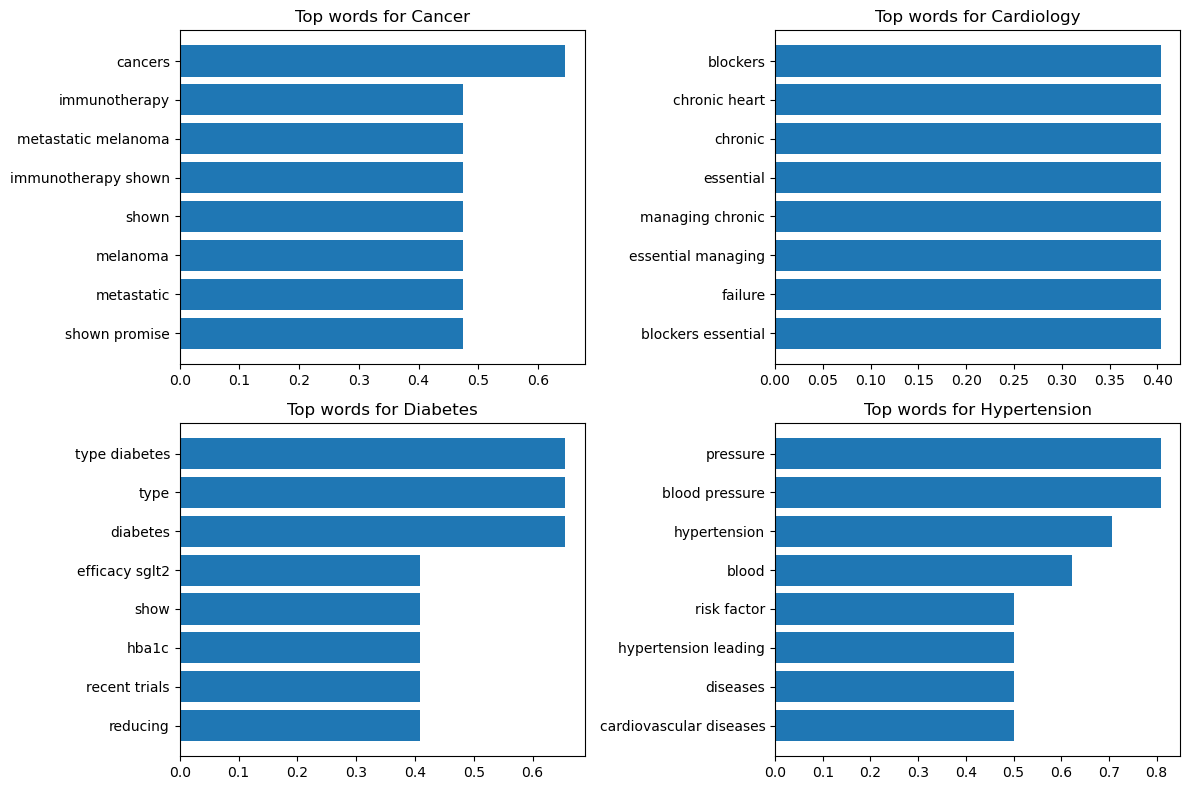

In [57]:
%matplotlib inline
import sys
if r"C:\Users\vhona" not in sys.path: sys.path.insert(0, r"C:\Users\vhona")
from helpers import get_features, get_tuned, plt
f = get_features()
grid = get_tuned()
best = grid.best_estimator_
terms = f['kept_terms']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cls, coefs in zip(axes.ravel(), best.classes_, best.coef_):
    idx = coefs.argsort()[-8:]
    ax.barh(terms[idx], coefs[idx])
    ax.set_title(f'Top words for {cls}')
plt.tight_layout()
plt.show()

Larger coefficients mean the word pushes a sentence more strongly toward that category. This shows what the model has learned.